In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("data_export_1.csv")

In [3]:
df.head()

,# ----------------------------------------,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9
0,Session primary channel group (Default channel...,Date + hour (YYYYMMDDHH),Users,Sessions,Engaged sessions,Average engagement time per session,Engaged sessions per user,Events per session,Engagement rate,Event count
1,Direct,2024041623,237,300,144,47.526666666666700,0.6075949367088610,4.673333333333330,0.48,1402
2,Organic Social,2024041719,208,267,132,32.09737827715360,0.6346153846153850,4.295880149812730,0.4943820224719100,1147
3,Direct,2024041723,188,233,115,39.93991416309010,0.6117021276595740,4.587982832618030,0.49356223175965700,1069
4,Organic Social,2024041718,187,256,125,32.16015625,0.6684491978609630,4.078125,0.48828125,1044


In [4]:
df.columns = df.iloc[0]
df = df.drop(index=0).reset_index(drop=True)
df.columns = [
    'channel_group', 'date_hour', 'users', 'sessions', 
    'engaged_sessions', 'average_engagement_time_per_session', 
    'engaged_sessions_per_user', 'events_per_session', 'engagement_rate', 'event_count'
]

In [5]:
df.head()

,channel_group,date_hour,users,sessions,engaged_sessions,average_engagement_time_per_session,engaged_sessions_per_user,events_per_session,engagement_rate,event_count
0,Direct,2024041623,237,300,144,47.526666666666700,0.6075949367088610,4.673333333333330,0.48,1402
1,Organic Social,2024041719,208,267,132,32.09737827715360,0.6346153846153850,4.295880149812730,0.4943820224719100,1147
2,Direct,2024041723,188,233,115,39.93991416309010,0.6117021276595740,4.587982832618030,0.49356223175965700,1069
3,Organic Social,2024041718,187,256,125,32.16015625,0.6684491978609630,4.078125,0.48828125,1044
4,Organic Social,2024041720,175,221,112,46.918552036199100,0.64,4.529411764705880,0.5067873303167420,1001


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3182 entries, 0 to 3181
Data columns (total 10 columns):
 #   Column                               Non-Null Count  Dtype 
---  ------                               --------------  ----- 
 0   channel_group                        3182 non-null   object
 1   date_hour                            3182 non-null   object
 2   users                                3182 non-null   object
 3   sessions                             3182 non-null   object
 4   engaged_sessions                     3182 non-null   object
 5   average_engagement_time_per_session  3182 non-null   object
 6   engaged_sessions_per_user            3182 non-null   object
 7   events_per_session                   3182 non-null   object
 8   engagement_rate                      3182 non-null   object
 9   event_count                          3182 non-null   object
dtypes: object(10)
memory usage: 248.7+ KB


In [7]:
df['date_hour'] = pd.to_datetime(df['date_hour'], format='%Y%m%d%H', errors='coerce')
numeric_cols = df.columns.drop(['channel_group', 'date_hour'])
df[numeric_cols] = df[numeric_cols].apply(pd.to_numeric)
df['hour'] = df['date_hour'].dt.hour

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3182 entries, 0 to 3181
Data columns (total 11 columns):
 #   Column                               Non-Null Count  Dtype         
---  ------                               --------------  -----         
 0   channel_group                        3182 non-null   object        
 1   date_hour                            3182 non-null   datetime64[ns]
 2   users                                3182 non-null   int64         
 3   sessions                             3182 non-null   int64         
 4   engaged_sessions                     3182 non-null   int64         
 5   average_engagement_time_per_session  3182 non-null   float64       
 6   engaged_sessions_per_user            3182 non-null   float64       
 7   events_per_session                   3182 non-null   float64       
 8   engagement_rate                      3182 non-null   float64       
 9   event_count                          3182 non-null   int64         
 10  hour        

In [9]:
df.describe()

,date_hour,users,sessions,engaged_sessions,average_engagement_time_per_session,engaged_sessions_per_user,events_per_session,engagement_rate,event_count,hour
count,3182,3182.000000,3182.000000,3182.000000,3182.000000,3182.000000,3182.000000,3182.000000,3182.000000,3182.000000
mean,2024-04-20 01:17:07.278441216,41.935889,51.192646,28.325581,66.644581,0.606450,4.675969,0.503396,242.272470,11.807040
min,2024-04-06 00:00:00,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,0.000000
25%,2024-04-13 02:15:00,20.000000,24.000000,13.000000,32.103034,0.561404,3.750000,0.442902,103.000000,6.000000
50%,2024-04-20 02:00:00,42.000000,51.000000,27.000000,49.020202,0.666667,4.410256,0.545455,226.000000,12.000000
75%,2024-04-26 22:00:00,60.000000,71.000000,41.000000,71.487069,0.750000,5.217690,0.633333,339.000000,18.000000
max,2024-05-03 23:00:00,237.000000,300.000000,144.000000,4525.000000,2.000000,56.000000,1.000000,1402.000000,23.000000
std,NaN,29.582258,36.919962,20.650569,127.200659,0.264023,2.795228,0.228206,184.440313,6.886686


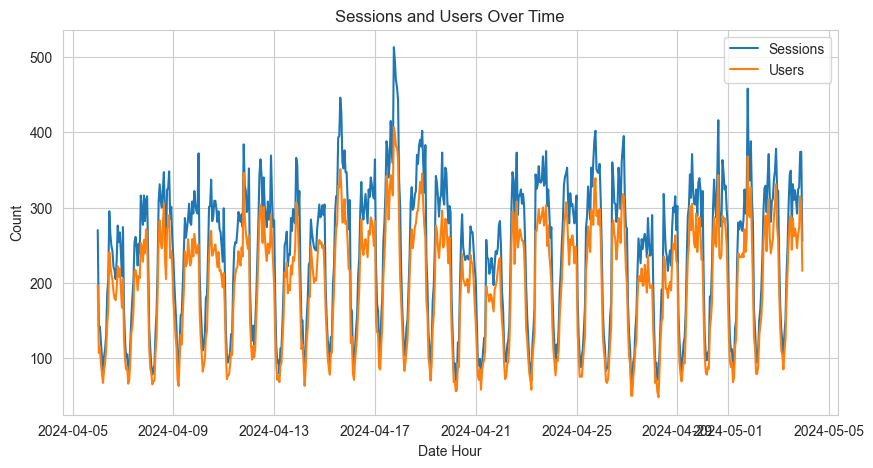

In [10]:
sns.set_style("whitegrid")
plt.figure(figsize=(10, 5))

df_time = df.groupby('date_hour')[['sessions', 'users']].sum()

plt.plot(df_time.index, df_time['sessions'], label='Sessions')
plt.plot(df_time.index, df_time['users'], label='Users')

plt.title('Sessions and Users Over Time')
plt.xlabel('Date Hour')
plt.ylabel('Count')
plt.legend()
plt.show()

C:\Users\dz laptops\AppData\Local\Temp\ipykernel_6768\1802849353.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='channel_group', y='users', estimator=np.sum, palette='viridis')


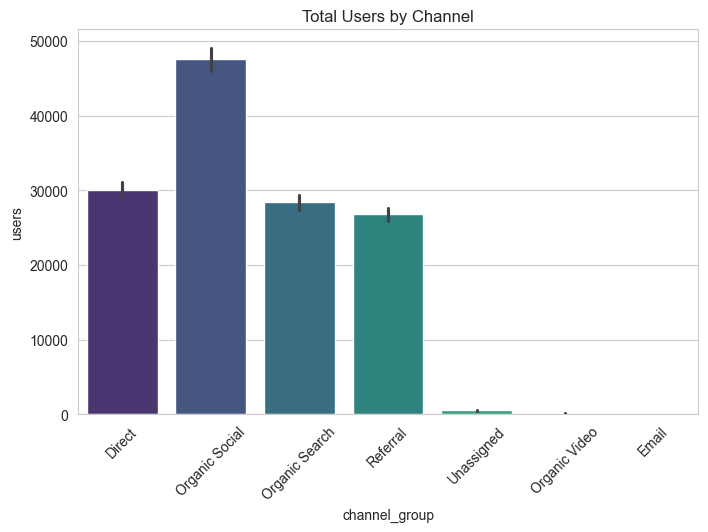

In [11]:
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x='channel_group', y='users', estimator=np.sum, palette='viridis')
plt.title('Total Users by Channel')
plt.xticks(rotation=45)
plt.show()

C:\Users\dz laptops\AppData\Local\Temp\ipykernel_6768\650160177.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='channel_group', y='average_engagement_time_per_session', estimator=np.mean, palette='magma')


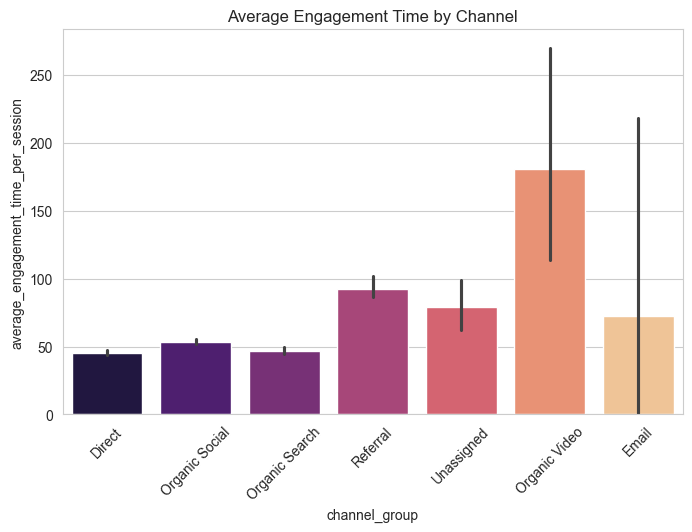

In [12]:
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x='channel_group', y='average_engagement_time_per_session', estimator=np.mean, palette='magma')
plt.title('Average Engagement Time by Channel')
plt.xticks(rotation=45)
plt.show()

C:\Users\dz laptops\AppData\Local\Temp\ipykernel_6768\3900320987.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='channel_group', y='engagement_rate', palette='coolwarm')


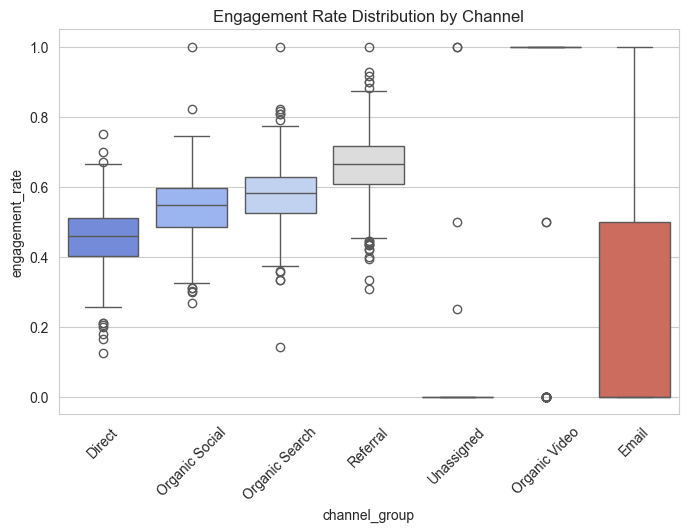

In [13]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='channel_group', y='engagement_rate', palette='coolwarm')
plt.title('Engagement Rate Distribution by Channel')
plt.xticks(rotation=45)
plt.show()

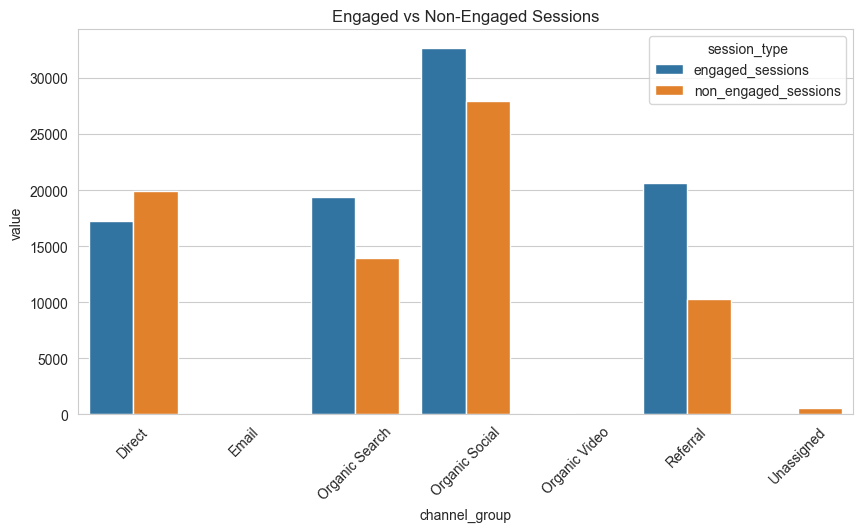

In [14]:
df_sessions = df.groupby('channel_group')[['sessions', 'engaged_sessions']].sum().reset_index()
df_sessions['non_engaged_sessions'] = df_sessions['sessions'] - df_sessions['engaged_sessions']
df_melted = df_sessions.melt(id_vars='channel_group', value_vars=['engaged_sessions', 'non_engaged_sessions'], var_name='session_type', value_name='value')

plt.figure(figsize=(10, 5))
sns.barplot(data=df_melted, x='channel_group', y='value', hue='session_type')
plt.title('Engaged vs Non-Engaged Sessions')
plt.xticks(rotation=45)
plt.show()

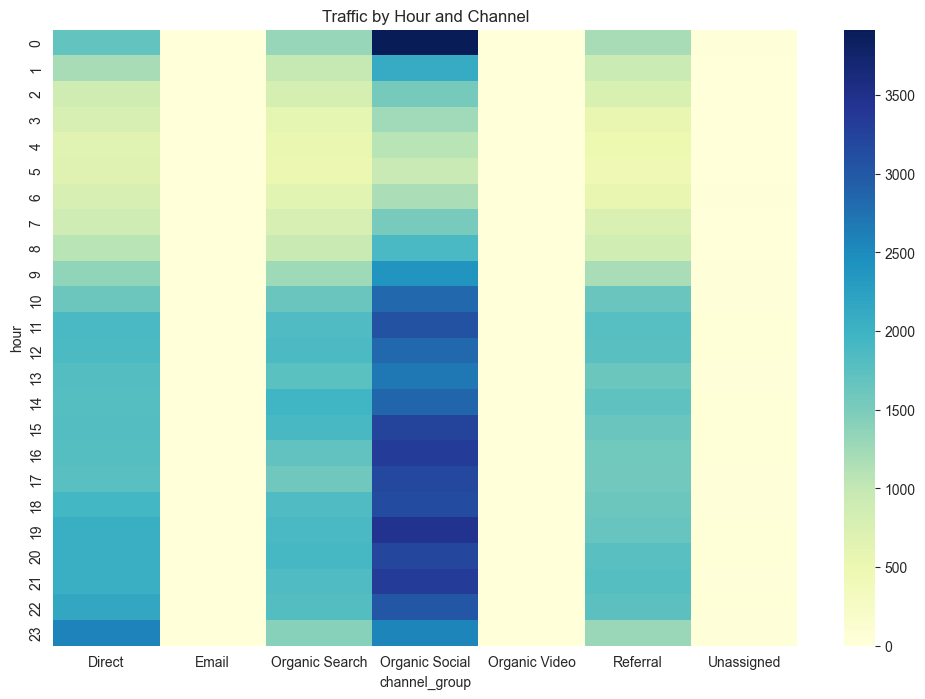

In [15]:
df_heatmap = df.groupby(['hour', 'channel_group'])['sessions'].sum().unstack().fillna(0)

plt.figure(figsize=(12, 8))
sns.heatmap(df_heatmap, cmap='YlGnBu')
plt.title('Traffic by Hour and Channel')
plt.show()

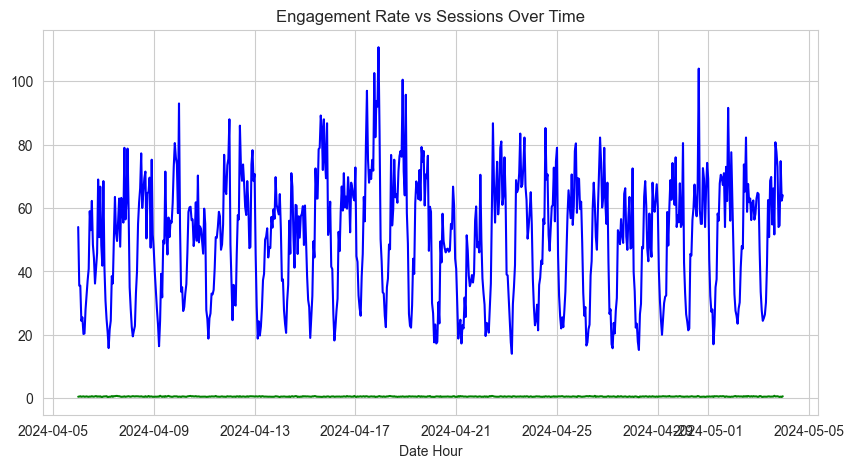

In [16]:
df_trend = df.groupby('date_hour')[['sessions', 'engagement_rate']].mean()

plt.figure(figsize=(10, 5))
plt.plot(df_trend.index, df_trend['sessions'], color='blue', label='Sessions')
plt.plot(df_trend.index, df_trend['engagement_rate'], color='green', label='Engagement Rate')

plt.title('Engagement Rate vs Sessions Over Time')
plt.xlabel('Date Hour')
plt.grid(True)
plt.show()